# AgriMarket Intelligence — Data Analysis & Crop Yield Prediction

This beginner-friendly notebook uses the dataset included in this project. It covers data loading, cleaning, exploratory data analysis (EDA), a basic Random Forest model, and export to Tableau.

**Important dataset note:** the included CSV contains soil, weather, crop, irrigation, fertilizer, pesticide, and crop-yield fields. It does **not** contain market prices, production totals, or area fields, so this notebook does not make market-price/revenue claims.

Run the cells **from top to bottom**. You do not need to run `data_pipeline.py` to use this notebook.

## 1. Import libraries and locate the dataset

In [2]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Works when Jupyter starts in the project root or in the notebooks folder.
# Find the dataset from the project folder
current_dir = Path.cwd().resolve()

search_dirs = [current_dir, *current_dir.parents]

csv_path = None

for folder in search_dirs:
    candidate = folder / "data" / "raw_agmarknet.csv"

    if candidate.is_file():
        csv_path = candidate
        break

if csv_path is None:
    print("Current working directory:", current_dir)
    raise FileNotFoundError(
        "Dataset not found. Check that the data folder contains "
        "raw_agmarknet.csv."
    )

PROJECT_ROOT = csv_path.parent.parent

df_raw = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File:", csv_path)
print("Rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

display(df_raw.head())

Dataset loaded successfully!
File: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\data\raw_agmarknet.csv
Rows and columns: (10000, 20)

Column names:
['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Soil_Type', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Region', 'Altitude', 'Season', 'Crop_Type', 'Irrigation_Type', 'Fertilizer_Used', 'Pesticide_Used', 'Crop_Yield_ton_per_hectare']


,N,P,K,Soil_pH,Soil_Moisture,Soil_Type,Organic_Carbon,Temperature,Humidity,Rainfall,Sunlight_Hours,Wind_Speed,Region,Altitude,Season,Crop_Type,Irrigation_Type,Fertilizer_Used,Pesticide_Used,Crop_Yield_ton_per_hectare
0,132,62,22,6.35,59.78,Clay,0.43,22.97,53.89,1305.68,7.73,15.96,Central,36,Rabi,Maize,Canal,223.48,23.36,11.42
1,122,71,66,5.98,25.54,Sandy,0.65,17.00,76.90,1942.05,9.25,12.60,North,1561,Rabi,Potato,Canal,161.54,4.42,23.19
2,44,35,104,8.07,25.87,Sandy,0.79,25.52,44.78,2216.20,8.50,15.63,North,1870,Rabi,Rice,Rainfed,184.62,6.29,7.94
3,136,96,113,4.83,42.97,Silt,0.45,18.59,31.89,607.18,8.75,5.49,East,765,Kharif,Sugarcane,Rainfed,274.02,2.72,72.53
4,101,34,42,5.84,48.01,Silt,0.69,22.74,46.27,483.47,8.00,7.44,Central,1143,Zaid,Wheat,Rainfed,72.69,15.37,6.72


## 2. Check column names and clean the data

In [3]:
# Normalize column names and text values.
df = df_raw.copy()
df.columns = [str(col).strip() for col in df.columns]
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Convert expected measurement fields to numeric values where possible.
expected_numeric = [
    "N", "P", "K", "Soil_pH", "Soil_Moisture", "Organic_Carbon",
    "Temperature", "Humidity", "Rainfall", "Sunlight_Hours", "Wind_Speed",
    "Altitude", "Fertilizer_Used", "Pesticide_Used", "Crop_Yield_ton_per_hectare"
]
for col in expected_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df = df.replace([np.inf, -np.inf], np.nan)

# Never invent target values: remove rows with missing crop-yield labels.
target = "Crop_Yield_ton_per_hectare"
if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found. Actual columns: {df.columns.tolist()}")
missing_target = int(df[target].isna().sum())
df = df.dropna(subset=[target]).copy()

# Fill missing input values: median for numeric, most frequent value for categorical.
for col in df.select_dtypes(include=[np.number]).columns:
    if col != target and df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=["object", "string", "category"]).columns:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        df[col] = df[col].fillna(mode.iloc[0] if not mode.empty else "Unknown")

print(f"Duplicate rows removed: {duplicates_before}")
print(f"Rows removed due to missing target: {missing_target}")
print("Cleaned shape:", df.shape)
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("missing_values"))

Duplicate rows removed: 0
Rows removed due to missing target: 0
Cleaned shape: (10000, 20)

Missing values after cleaning:


,missing_values
N,0
P,0
K,0
Soil_pH,0
Soil_Moisture,0
Soil_Type,0
Organic_Carbon,0
Temperature,0
Humidity,0
Rainfall,0


## 3. Explore the dataset

In [4]:
print("Dataset summary")
display(df.describe(include="all").T)

for col in ["Crop_Type", "Region", "Season", "Soil_Type", "Irrigation_Type"]:
    if col in df.columns:
        print(f"\nUnique values in {col}: {df[col].nunique()}")
        print(sorted(df[col].dropna().astype(str).unique().tolist()))

Dataset summary


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,10000.0,NaN,NaN,NaN,104.983,43.291654,30.0,68.0,105.0,142.0,179.0
P,10000.0,NaN,NaN,NaN,56.8096,24.522962,15.0,35.0,57.0,78.0,99.0
K,10000.0,NaN,NaN,NaN,85.0087,37.541443,20.0,52.0,85.0,118.0,149.0
Soil_pH,10000.0,NaN,NaN,NaN,6.504306,0.978698,4.8,5.67,6.52,7.35,8.2
Soil_Moisture,10000.0,NaN,NaN,NaN,40.083748,14.461944,15.0,27.63,40.0,52.7625,64.99
Soil_Type,10000,4,Loamy,2543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Organic_Carbon,10000.0,NaN,NaN,NaN,0.958356,0.375027,0.3,0.63,0.96,1.29,1.6
Temperature,10000.0,NaN,NaN,NaN,25.097402,8.719031,10.0,17.59,24.97,32.83,40.0
Humidity,10000.0,NaN,NaN,NaN,59.894209,17.40245,30.01,44.83,59.55,75.0375,89.99
Rainfall,10000.0,NaN,NaN,NaN,1546.694887,718.86596,300.7,925.7675,1548.55,2165.4525,2799.26



Unique values in Crop_Type: 6
['Cotton', 'Maize', 'Potato', 'Rice', 'Sugarcane', 'Wheat']

Unique values in Region: 5
['Central', 'East', 'North', 'South', 'West']

Unique values in Season: 3
['Kharif', 'Rabi', 'Zaid']

Unique values in Soil_Type: 4
['Clay', 'Loamy', 'Sandy', 'Silt']

Unique values in Irrigation_Type: 4
['Canal', 'Drip', 'Rainfed', 'Sprinkler']


## 4. Crop-yield analysis

Average crop yield by crop type


,average_yield_ton_per_hectare
Crop_Type,
Sugarcane,74.83
Potato,24.89
Maize,10.08
Rice,9.40
Wheat,8.72
Cotton,7.43


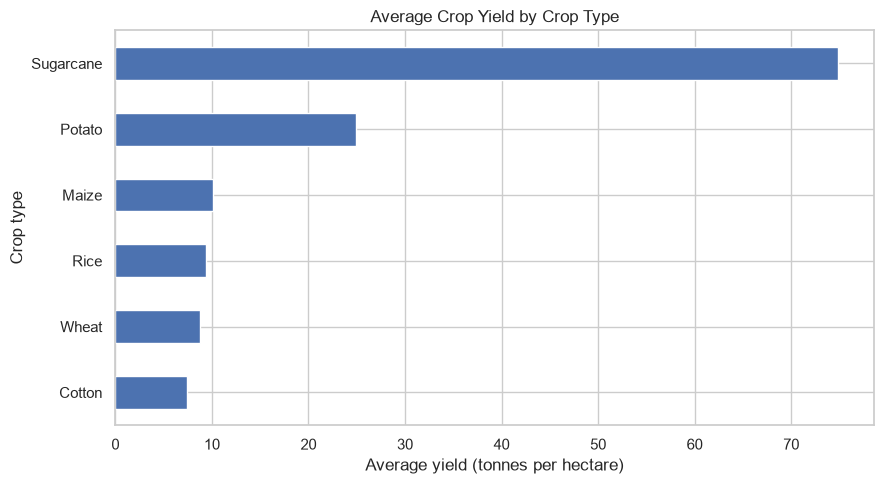

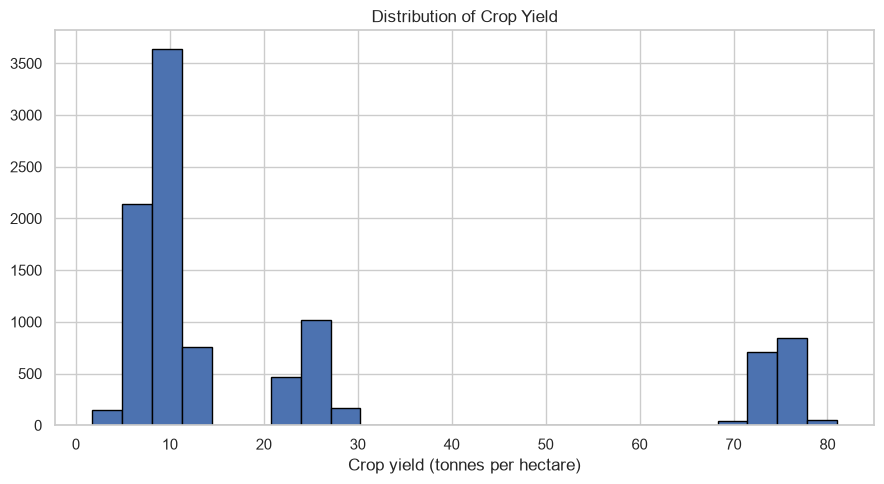

In [5]:
target = "Crop_Yield_ton_per_hectare"
print("Average crop yield by crop type")
yield_by_crop = df.groupby("Crop_Type")[target].mean().sort_values(ascending=False)
display(yield_by_crop.to_frame("average_yield_ton_per_hectare").round(2))

yield_by_crop.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Average Crop Yield by Crop Type")
plt.xlabel("Average yield (tonnes per hectare)")
plt.ylabel("Crop type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(df[target].dropna(), bins=25, edgecolor="black")
plt.title("Distribution of Crop Yield")
plt.xlabel("Crop yield (tonnes per hectare)")
plt.tight_layout()
plt.show()

## 5. Correlation between numeric fields

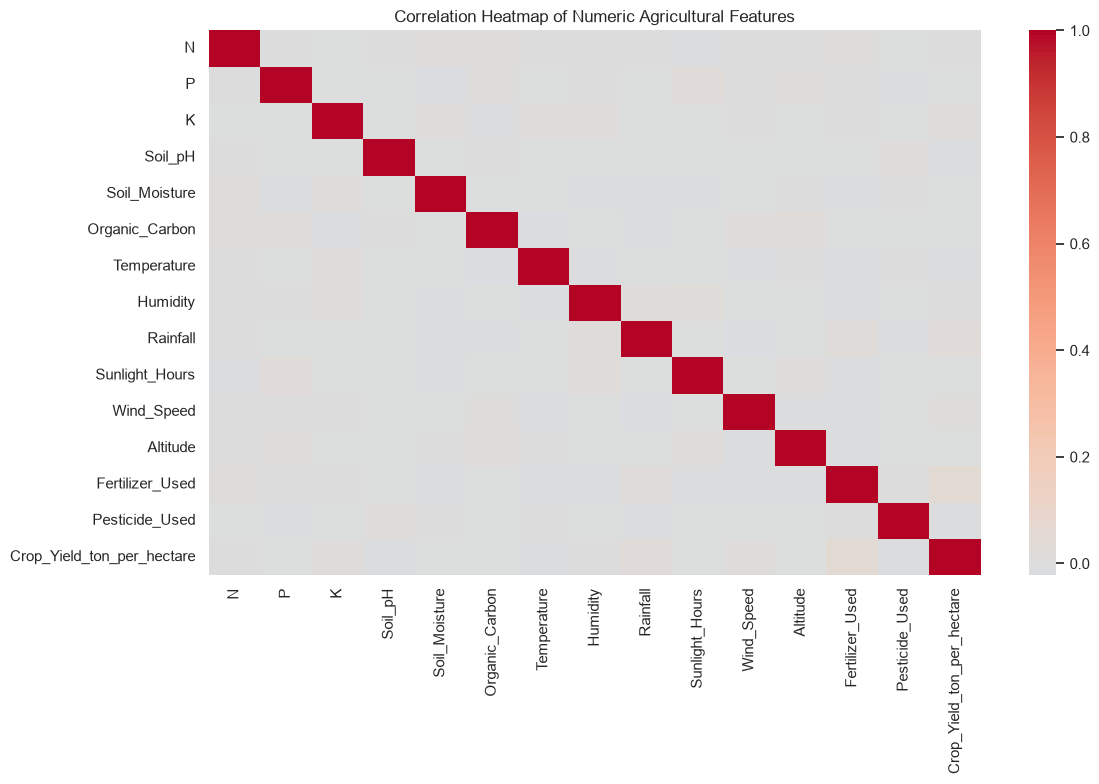

Correlation with crop yield (highest absolute values first):


,correlation_with_yield
Fertilizer_Used,0.051371
Rainfall,0.031213
Wind_Speed,0.015185
Pesticide_Used,-0.012060
Soil_pH,-0.010509
K,0.009897
Humidity,0.006916
Temperature,-0.006589
P,-0.002483
N,0.002334


In [6]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Agricultural Features")
plt.tight_layout()
plt.show()

if target in corr.columns:
    print("Correlation with crop yield (highest absolute values first):")
    display(corr[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_yield"))

## 6. Compare yield by season, region, and irrigation

Average crop yield by Season


,average_yield_ton_per_hectare
Season,
Rabi,22.80
Kharif,22.43
Zaid,21.79


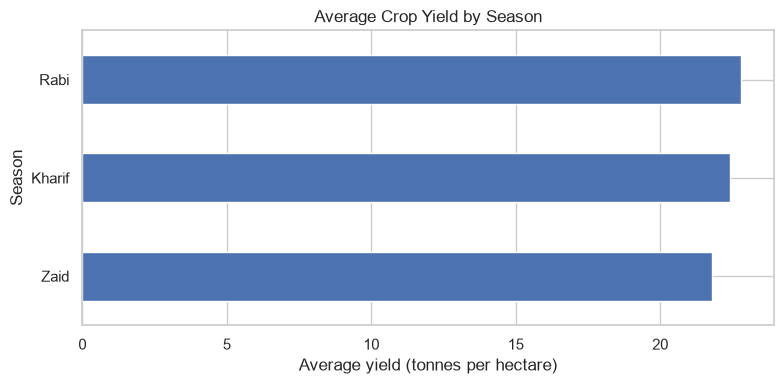

Average crop yield by Region


,average_yield_ton_per_hectare
Region,
West,23.10
South,22.57
Central,22.54
East,22.44
North,21.07


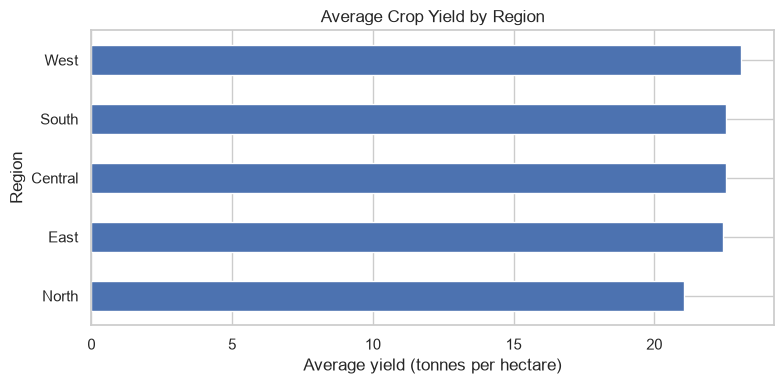

Average crop yield by Irrigation_Type


,average_yield_ton_per_hectare
Irrigation_Type,
Sprinkler,22.90
Drip,22.34
Canal,22.20
Rainfed,21.96


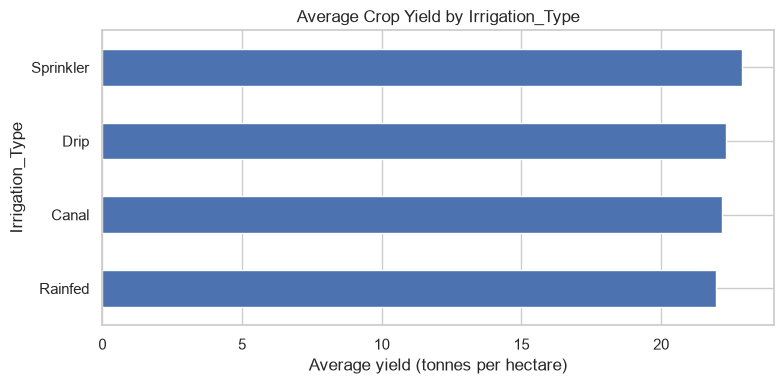

Average crop yield by Soil_Type


,average_yield_ton_per_hectare
Soil_Type,
Silt,22.82
Clay,22.69
Loamy,22.60
Sandy,21.26


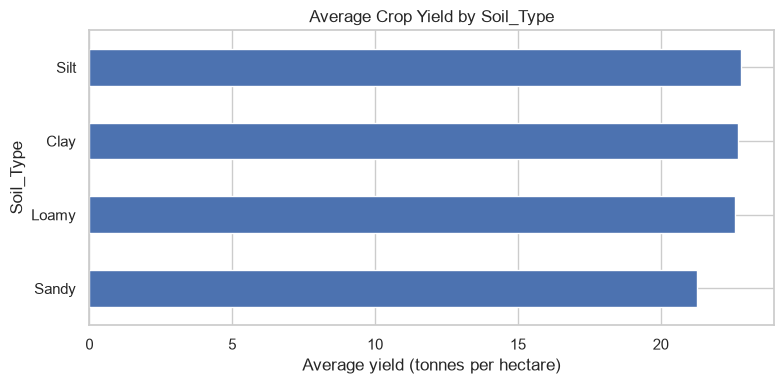

In [7]:
for col in ["Season", "Region", "Irrigation_Type", "Soil_Type"]:
    if col in df.columns:
        summary = df.groupby(col, dropna=False)[target].mean().sort_values(ascending=False)
        print(f"Average crop yield by {col}")
        display(summary.to_frame("average_yield_ton_per_hectare").round(2))
        summary.sort_values().plot(kind="barh", figsize=(8, 4))
        plt.title(f"Average Crop Yield by {col}")
        plt.xlabel("Average yield (tonnes per hectare)")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

## 7. Chi-square test: season and crop type

In [8]:
from scipy.stats import chi2_contingency

if "Season" in df.columns and "Crop_Type" in df.columns:
    contingency = pd.crosstab(df["Season"], df["Crop_Type"])
    display(contingency)
    if contingency.shape[0] > 1 and contingency.shape[1] > 1:
        chi2, p_value, dof, expected = chi2_contingency(contingency)
        print(f"Chi-square statistic: {chi2:.3f}")
        print(f"p-value: {p_value:.6g}")
        print(f"Degrees of freedom: {dof}")
        print("Interpretation: statistically significant association at 5% level." if p_value < 0.05 else "Interpretation: no statistically significant association at 5% level.")
    else:
        print("Not enough categories for a chi-square test.")
else:
    print("Season or Crop_Type column is missing; skipping test.")

Crop_Type,Cotton,Maize,Potato,Rice,Sugarcane,Wheat
Season,,,,,,
Kharif,556,524,577,576,546,571
Rabi,547,545,572,565,569,557
Zaid,563,589,521,561,518,543


Chi-square statistic: 10.359
p-value: 0.409608
Degrees of freedom: 10
Interpretation: no statistically significant association at 5% level.


## 8. Machine Learning: predict crop yield

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Predict crop yield from soil, weather, crop, and farm-management features.
# The target itself is removed from the input features to avoid target leakage.
X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = r2_score(y_test, y_pred)
metrics = {"target": target, "rows": int(len(df)), "test_rows": int(len(y_test)), "MAE": float(mae), "RMSE": rmse, "R2": float(r2)}
print("Random Forest evaluation on held-out test data")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")
print("\nNote: these scores describe this dataset and split; they do not guarantee real-world prediction accuracy.")

Random Forest evaluation on held-out test data
MAE:  0.903
RMSE: 1.132
R²:   0.998

Note: these scores describe this dataset and split; they do not guarantee real-world prediction accuracy.


## 9. Feature importance

,feature,importance
30,categorical__Crop_Type_Sugarcane,0.933806
28,categorical__Crop_Type_Potato,0.060217
12,numeric__Fertilizer_Used,0.001445
8,numeric__Rainfall,0.001056
26,categorical__Crop_Type_Cotton,0.000837
4,numeric__Soil_Moisture,0.000495
3,numeric__Soil_pH,0.000276
10,numeric__Wind_Speed,0.000226
0,numeric__N,0.000186
2,numeric__K,0.000180


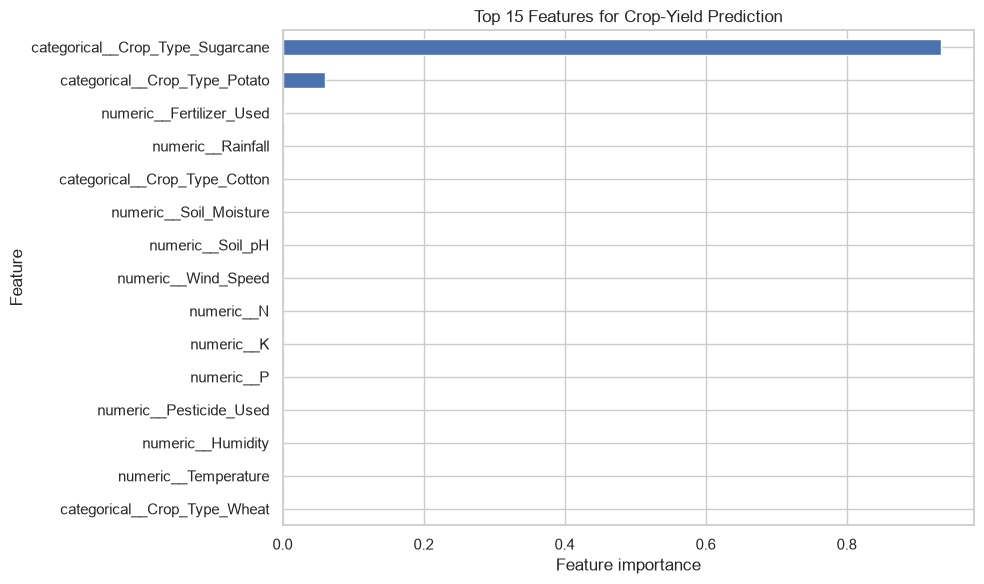

In [10]:
try:
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()
    importances = model.named_steps["regressor"].feature_importances_
    feature_importance = pd.DataFrame({"feature": feature_names, "importance": importances})
    feature_importance = feature_importance.sort_values("importance", ascending=False)
    display(feature_importance.head(15))
    feature_importance.head(15).sort_values("importance").plot(
        x="feature", y="importance", kind="barh", legend=False, figsize=(10, 6)
    )
    plt.title("Top 15 Features for Crop-Yield Prediction")
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
except (AttributeError, ValueError) as exc:
    feature_importance = pd.DataFrame(columns=["feature", "importance"])
    print("Could not extract feature names in this scikit-learn version:", exc)

## 10. Export the cleaned data and ML results

In [11]:
# Save the cleaned dataset in the project's data folder for Tableau.
output_csv = PROJECT_ROOT / "data" / "cleaned_agriculture_data.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_csv, index=False)

reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
with (reports_dir / "model_metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
if not feature_importance.empty:
    feature_importance.to_csv(reports_dir / "feature_importance.csv", index=False)

predictions = pd.DataFrame({"actual_yield": y_test.to_numpy(), "predicted_yield": y_pred})
predictions.to_csv(reports_dir / "yield_predictions.csv", index=False)

print("Cleaned CSV saved to:", output_csv)
print("Model metrics saved to:", reports_dir / "model_metrics.json")
print("Feature importance saved to:", reports_dir / "feature_importance.csv")
print("Predictions saved to:", reports_dir / "yield_predictions.csv")
print("\nDone! You can now connect data/cleaned_agriculture_data.csv to Tableau.")

Cleaned CSV saved to: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\data\cleaned_agriculture_data.csv
Model metrics saved to: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\reports\model_metrics.json
Feature importance saved to: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\reports\feature_importance.csv
Predictions saved to: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\reports\yield_predictions.csv

Done! You can now connect data/cleaned_agriculture_data.csv to Tableau.


In [12]:
%pip install numpy pandas matplotlib seaborn scikit-learn scipy joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 11. Use the cleaned dataset in Tableau

1. Run all notebook cells successfully.
2. Open Tableau Desktop.
3. Choose **Connect → Text File** and select `data/cleaned_agriculture_data.csv`.
4. Build charts using the fields that actually exist in this dataset, for example:
   - Average crop yield by `Crop_Type`
   - Average crop yield by `Region` or `Season`
   - Rainfall vs. crop yield
   - Soil pH vs. crop yield
   - Yield by `Irrigation_Type` or `Soil_Type`
5. Save the finished Tableau workbook as a packaged workbook (`.twbx`) if required.

**Scope reminder:** the supplied data supports crop-yield and agricultural-condition analysis, not market-price analysis. A true market-intelligence dashboard would need a separate market-price dataset.